# One site of a particle as the sample: where does OH bind?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/32_sites_on_a_particle.ipynb)

Notebook 24 predicts a property of a whole metal particle. A catalyst chemist often asks a
different question: **which atom of the particle binds an adsorbate most strongly?** Here the
sample is one surface site, and the target is the binding energy of OH atop that site.

The data are 48 particles of platinum and gold with 38 to 147 atoms: eight shapes, each perfect
and with 3 or 8 surface atoms removed. OH was placed atop every surface site and relaxed with the
UMA machine-learned potential (plan item NT7). The binding energy is given relative to OH atop
the (111) terrace of the same metal, in eV. A negative value means a stronger bond than on the
terrace.

The notebook asks four questions.

1. Does the binding follow the **generalized coordination number** of the site, as Calle-Vallejo
   and co-workers found for platinum?
2. Which description of a site predicts the binding on particles the model has never seen: a
   **site profile** (the fields around the site, with or without the core fields), simple counts,
   or the coordination numbers?
3. How much of the best model can a few numbers of the site replace? This reference is new in
   this notebook.
4. Does the best model find the strongest site of a new particle, and can a model of the whole
   particle say which site that is?

A part runs live, with the shapes held out. The rest reads the stored results of
`benchmarks/run_particle_sites.py`.

Running time: about one minute.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data

`examples/particle_sites` holds the particles (`particles.extxyz`) and one row per surface atom
(`sites.csv`). Sites with the same environment were computed once; a sample here is one computed
site. Some sites are left out: there the OH did not stay atop its own atom, mostly beside a
removed atom, where the normal of the site points into the hole.

In [2]:
import json
import time
import warnings

import numpy as np

warnings.filterwarnings("ignore")
sys.path.insert(0, "benchmarks")
import run_particle_sites as PS              # the benchmark script of plan item NT7
from run_shape import _group_splits, _per_metal, _scores

start = time.time()
D = PS.load()
y = D["targets"].y
metal, shape, particle = D["metal"], D["shape"], D["particle"]
C = PS.site_columns(D)
print("%d particles, %d computed sites, %d sites left out (OH not bound atop)"
      % (len(D["particles"]), len(y), D["moved"]))
print("shapes:", ", ".join(sorted(set(shape))))
for el in PS.METALS:
    m = metal == el
    print("%s: %4d sites, binding %+.2f to %+.2f eV, standard deviation %.3f eV"
          % (el, m.sum(), y[m].min(), y[m].max(), y[m].std()))

48 particles, 1851 computed sites, 239 sites left out (OH not bound atop)
shapes: cubo55, deca147, deca55, ico147, ico55, octa4, octa5, octa6
Au:  915 sites, binding -0.84 to +0.08 eV, standard deviation 0.211 eV
Pt:  936 sites, binding -1.26 to +0.75 eV, standard deviation 0.336 eV


## The binding follows the generalized coordination number

The **coordination number** (CN) of a site counts its metal neighbours. The **generalized
coordination number** (GCN) also counts the neighbours of those neighbours: it is the sum of the
CN of every neighbour, divided by 12, the CN of an atom in the bulk. A site with fewer and less
coordinated neighbours binds more strongly. The cell fits a straight line for each metal and
plots it.

Au: slope +0.150 eV per unit of GCN, correlation 0.914
Pt: slope +0.219 eV per unit of GCN, correlation 0.835


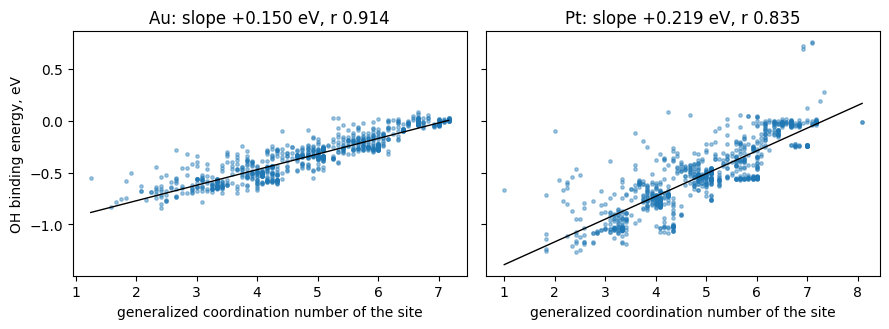

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, el in zip(axes, PS.METALS):
    m = metal == el
    slope, intercept = np.polyfit(C["gcn"][m], y[m], 1)
    r = np.corrcoef(C["gcn"][m], y[m])[0, 1]
    ax.scatter(C["gcn"][m], y[m], s=6, alpha=0.4)
    xs = np.linspace(C["gcn"][m].min(), C["gcn"][m].max(), 2)
    ax.plot(xs, intercept + slope * xs, color="black", lw=1)
    ax.set_title("%s: slope %+.3f eV, r %.3f" % (el, slope, r))
    ax.set_xlabel("generalized coordination number of the site")
    print("%s: slope %+.3f eV per unit of GCN, correlation %.3f" % (el, slope, r))
axes[0].set_ylabel("OH binding energy, eV")
plt.tight_layout()
plt.show()

**Both metals follow the generalized coordination number.** The binding weakens by 0.150 eV per
unit of GCN on gold (correlation 0.914) and by 0.219 eV on platinum (0.835). A site with fewer
and less coordinated neighbours binds more strongly, as Calle-Vallejo and co-workers found for
platinum. The line still leaves much of the spread: 1 - 0.835² = 30 % of the variance on
platinum and 17 % on gold. One number is not a full description of a site.

## Describing one site

Every model gets the same samples and is tested on sites of particles it has never seen. They
differ in how a site is described.

- **Linear regressions for each metal** on the CN or on the GCN of the site.
- **Counts**: the number of metal atoms in four distance shells around the site (up to 2, 3, 4.5
  and 6 A), with the CN and the GCN, in a Gaussian kernel for each metal.
- **A site profile** (plan item M5): the autocorrelation of the fields of the atoms within 6 A of
  the site, read from the site. The fields are steric, electronegativity and one indicator per
  metal; with the **core fields** of plan item NT6 they also include the CN, the GCN and the
  **exposure** of every atom (how open the space around the atom is).
- **Numbers of the site** (new here): the counts, the CN and the GCN, and also the exposure of the
  site. A second version adds, for each distance shell, the sums of the CN, the GCN and the
  exposure over the atoms in the shell. These hold what the core fields hold, without a kernel
  over the distances.

The live cell holds out each of the eight shapes in turn, in both metals and all three variants.
This is the harder test: the same shape in the other metal is a near copy, so holding out single
particles would leave it in the training set. The site profile chooses its ridge parameter by an
inner cross-validation, as in the benchmark. The Gaussian kernels use the width and the ridge
parameter that the benchmark chose most often on this split, read from the stored results.

In [4]:
from cmfqsar.periodic import crystal_table, inorganic_fieldset
from cmfqsar.sites import SHELLS, shell_count_features

with open("benchmarks/results/particle_sites/references.json", encoding="utf-8") as fh:
    REF = json.load(fh)
with open("benchmarks/results/particle_sites/model.json", encoding="utf-8") as fh:
    MODEL = json.load(fh)

plain = inorganic_fieldset(list(PS.METALS), physchem=PS.PHYSCHEM, other=False)
crystals = list(crystal_table(D["particles"], plain, D["names"]).molecules)
counts = shell_count_features(crystals, D["targets"], elements=list(PS.METALS))
counts = counts[:, counts.any(axis=0)]
numbers = PS.site_numbers(D, counts, SHELLS)
kern = PS.SiteKernels(D, {"core": inorganic_fieldset(list(PS.METALS), physchem=PS.PHYSCHEM,
                                                     other=False, core=True)})
same = (metal[:, None] == metal[None, :]).astype(float)


def gaussian_fixed(X, train, test, gamma, lam):
    """A Gaussian kernel on the standardised columns, zero between the two metals."""
    Z = (X - X[train].mean(0)) / (X[train].std(0) + 1e-12)
    sq = (Z * Z).sum(1)
    d2 = np.maximum(sq[:, None] + sq[None, :] - 2 * Z @ Z.T, 0.0) / Z.shape[1]
    K = np.exp(-gamma * d2) * same
    a = np.linalg.solve(K[np.ix_(train, train)] + lam * np.eye(len(train)),
                        y[train] - y[train].mean())
    return K[np.ix_(test, train)] @ a + y[train].mean()


def most_chosen(name):
    chosen = REF["shapes"]["models"][name]["chosen"]
    setting = max(chosen, key=chosen.get)
    return tuple(float(v) for v in setting.split("/"))


folds = [(np.flatnonzero(shape == g), np.flatnonzero(shape != g)) for g in sorted(set(shape))]
models = {
    "linear on the CN, for each metal": lambda tr, te: _per_metal(metal, C["cn"][:, None], y, tr, te),
    "linear on the GCN, for each metal": lambda tr, te: _per_metal(metal, C["gcn"][:, None], y, tr, te),
    "counts, CN and GCN": lambda tr, te: gaussian_fixed(numbers[PS.REFERENCES[0]], tr, te,
                                                         *most_chosen(PS.REFERENCES[0])),
    "the same and the exposure of the site": lambda tr, te: gaussian_fixed(
        numbers[PS.REFERENCES[1]], tr, te, *most_chosen(PS.REFERENCES[1])),
    "site profile with the core fields": lambda tr, te: kern.predict("core", y, tr, te, 0, shape)}
stored = {"counts, CN and GCN": REF["shapes"]["models"][PS.REFERENCES[0]]["q2"],
          "the same and the exposure of the site": REF["shapes"]["models"][PS.REFERENCES[1]]["q2"],
          "site profile with the core fields": REF["shapes"]["models"][PS.PROFILE]["q2"],
          "linear on the CN, for each metal":
              MODEL["shapes"]["linear regression on the coordination number, for each metal"]["q2"],
          "linear on the GCN, for each metal":
              MODEL["shapes"]["linear regression on the generalized coordination number, for each metal"]["q2"]}
live = {}
print("%-40s %10s %10s" % ("each shape held out", "q2, live", "benchmark"))
for name, fn in models.items():
    p = np.full(len(y), np.nan)
    for te, tr in folds:
        p[te] = fn(tr, te)
    live[name] = p
    print("%-40s %10.3f %10.3f" % (name, _scores(y, p, y.mean())["q2"], stored[name]))
print("(%.0f s so far)" % (time.time() - start))

site profiles core: (1851, 364), 1.1 s


each shape held out                        q2, live  benchmark
linear on the CN, for each metal              0.781      0.781
linear on the GCN, for each metal             0.711      0.711


counts, CN and GCN                            0.879      0.855


the same and the exposure of the site         0.909      0.904


site profile with the core fields             0.920      0.920
(52 s so far)


**With the shapes held out, the site profile with the core fields predicts best: q² 0.920.** The
linear regressions on the CN and on the GCN reach 0.781 and 0.711. The Gaussian kernel on the
counts, the CN and the GCN reaches 0.879 here, and **adding one more number, the exposure of the
site, raises it to 0.909**, close to the profile.

The profile and the regressions repeat the benchmark exactly. The two Gaussian kernels differ a
little from it (0.855 and 0.904 there), because this cell fixes the width and the ridge parameter
that the benchmark chose most often, while the benchmark chooses them again in every fold.

The next cell plots the live predictions of two models against the computed energies: the
site profile with the core fields, and the Gaussian kernel on the numbers of the site with the
exposure. Each point is one site of a particle whose shape was held out.

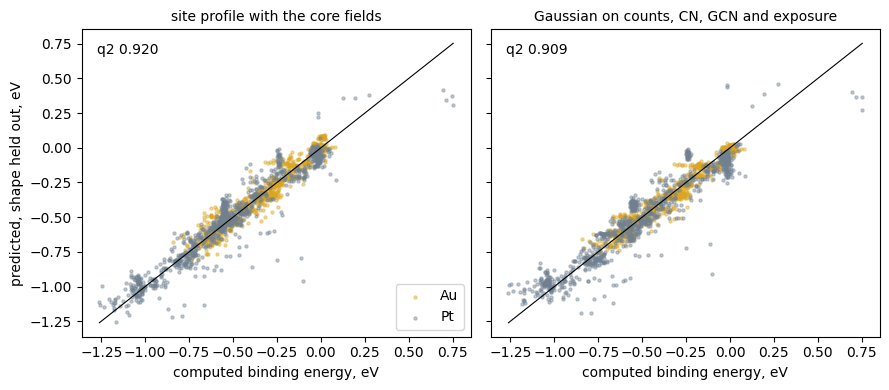

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ("site profile with the core fields", "the same and the exposure of the site")):
    for el, colour in zip(PS.METALS, ("goldenrod", "slategrey")):
        m = metal == el
        ax.scatter(y[m], live[name][m], s=5, alpha=0.4, color=colour, label=el)
    lims = [min(y.min(), live[name].min()), max(y.max(), live[name].max())]
    ax.plot(lims, lims, color="black", lw=0.8)
    ax.set_title(name if name.startswith("site") else "Gaussian on counts, CN, GCN and exposure", fontsize=10)
    ax.set_xlabel("computed binding energy, eV")
    ax.text(0.04, 0.92, "q2 %.3f" % _scores(y, live[name], y.mean())["q2"], transform=ax.transAxes)
axes[0].set_ylabel("predicted, shape held out, eV")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

The cell below draws one particle, a platinum cuboctahedron of 55 atoms with three surface
atoms removed. Each coloured atom is a computed site (one of each set of equivalent sites); grey
atoms are the core, the equivalent copies, and the sites left out. The left panel gives the
computed binding, the right panel the prediction of the site profile with this shape held out.
The red ring marks the site that binds most strongly in each panel.

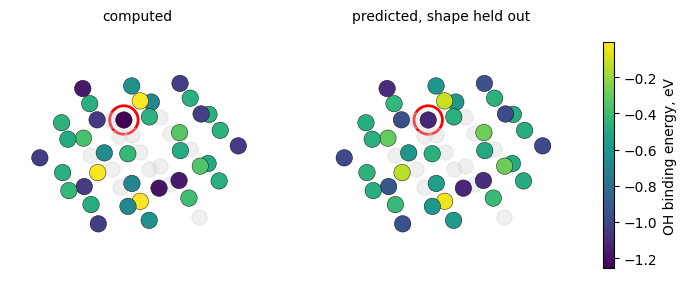

Pt_cubo55_r3: strongest computed site 2 (-1.256 eV), predicted strongest site 2 (computed -1.256 eV)


In [6]:
name = "Pt_cubo55_r3"
k = D["names"].index(name)
pos = D["particles"][k].get_positions()
rows = np.flatnonzero(particle == name)
sites = D["targets"].atom[rows].astype(int)
values = {"computed": y[rows], "predicted, shape held out": live["site profile with the core fields"][rows]}
low = min(v.min() for v in values.values())
high = max(v.max() for v in values.values())
fig = plt.figure(figsize=(9, 4.2))
for j, (title, v) in enumerate(values.items()):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    ax.scatter(*pos.T, s=120, color="lightgrey", alpha=0.35, depthshade=False)
    points = ax.scatter(*pos[sites].T, c=v, cmap="viridis", vmin=low, vmax=high, s=140,
                        edgecolors="black", linewidths=0.3, depthshade=False)
    best = sites[int(np.argmin(v))]
    ax.scatter(*pos[best], s=420, facecolors="none", edgecolors="red", linewidths=2)
    ax.set_title(title, fontsize=10)
    ax.view_init(elev=20, azim=35)
    ax.set_axis_off()
fig.colorbar(points, ax=fig.axes, shrink=0.7, label="OH binding energy, eV")
plt.show()
computed_best = sites[int(np.argmin(values["computed"]))]
predicted_best = sites[int(np.argmin(values["predicted, shape held out"]))]
print("%s: strongest computed site %d (%.3f eV), predicted strongest site %d (computed %.3f eV)"
      % (name, computed_best, values["computed"].min(), predicted_best,
         y[rows][list(sites).index(predicted_best)]))

## All models, with intervals

The cell prints the stored results of the benchmark for both tests: five folds that hold out
whole particles (repeated with five seeds), and the eight folds that hold out shapes. The last two
columns give the difference of q² between the site profile with the core fields and each
reference, with a 95 % interval from a bootstrap that resamples whole particles.

In [7]:
TITLES = {
    "site profile, steric, electronegativity and one indicator per metal": "site profile without core fields",
    "the same and the three core fields of NT6": "site profile with the core fields",
    "linear regression on the generalized coordination number, for each metal": "linear on the GCN, for each metal",
    "linear regression on the coordination number, for each metal": "linear on the CN, for each metal",
    "linear regression on the atoms in four distance shells, for each metal": "linear on the shell counts, for each metal"}
print("%-58s %10s %10s" % ("model", "particles", "shapes"))
for name, short in TITLES.items():
    print("%-58s %10.3f %10.3f" % (short, MODEL["particles"][name]["q2"], MODEL["shapes"][name]["q2"]))
for name in PS.REFERENCES:
    print("%-58s %10.3f %10.3f" % ("Gaussian on " + name, REF["particles"]["models"][name]["q2"],
                                   REF["shapes"]["models"][name]["q2"]))
print()
print("site profile with the core fields minus ...")
for name in PS.REFERENCES:
    cells = []
    for scheme in ("particles", "shapes"):
        c = next(c for c in REF[scheme]["comparisons"] if c["against"] == name)
        cells.append("%+.3f [%+.3f, %+.3f]" % (c["mean"], c["lo"], c["hi"]))
    print("   %-62s particles %s   shapes %s" % (name, cells[0], cells[1]))

model                                                       particles     shapes
site profile without core fields                                0.744      0.754
site profile with the core fields                               0.929      0.920
linear on the GCN, for each metal                               0.736      0.711
linear on the CN, for each metal                                0.800      0.781
linear on the shell counts, for each metal                      0.830      0.802
Gaussian on counts and both coordination numbers                0.902      0.855
Gaussian on the same and the exposure of the site               0.927      0.904
Gaussian on the same and the core values summed over each distance shell      0.933      0.900

site profile with the core fields minus ...
   counts and both coordination numbers                           particles +0.025 [-0.005, +0.052]   shapes +0.065 [+0.029, +0.107]
   the same and the exposure of the site                          particles +0.

**Most of what the core fields add is one number of the site, its exposure.** Without the core
fields the profile reaches only 0.744 and 0.754, below the counts. With them it reaches 0.929 and
0.920. The Gaussian kernel on the counts and the two coordination numbers is 0.025 behind with
particles held out (the interval includes zero) and 0.065 [+0.029, +0.107] behind with shapes held
out. With the exposure of the site added, the gap is +0.004 [-0.021, +0.021] and +0.016 [-0.002,
+0.033]: both intervals include zero.

**With the core values of each distance shell added as well**, the numbers of the site are level
with the profile when particles are held out (0.933 against 0.929; -0.005 [-0.025, +0.009]). On a
new shape the profile keeps a small lead: +0.020 [+0.007, +0.037]. So a profile over the
distances adds something only when the shape is new, and then about 0.02 in q².

**A note on fairness.** The two new references were given grids of the width and the ridge
parameter wider at both ends than the benchmark's own, because a first run chose the edge of
that grid in a few folds. The reference with the shell sums still chose the smallest width in 4
of 33 folds, but the wider grid changed its q² by less than 0.001.

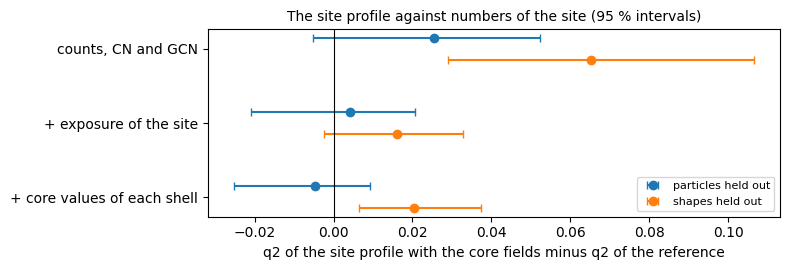

In [8]:
fig, ax = plt.subplots(figsize=(8, 2.8))
labels = ["counts, CN and GCN", "+ exposure of the site", "+ core values of each shell"]
for j, (scheme, colour) in enumerate((("particles", "tab:blue"), ("shapes", "tab:orange"))):
    for i, name in enumerate(PS.REFERENCES):
        c = next(c for c in REF[scheme]["comparisons"] if c["against"] == name)
        yy = i + (0.15 if j else -0.15)
        ax.errorbar(c["mean"], yy, xerr=[[c["mean"] - c["lo"]], [c["hi"] - c["mean"]]], fmt="o",
                    color=colour, capsize=3, label=("%s held out" % scheme) if i == 0 else None)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(3))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("q2 of the site profile with the core fields minus q2 of the reference")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("The site profile against numbers of the site (95 % intervals)", fontsize=10)
plt.tight_layout()
plt.show()

## The strongest site of a new particle

A catalyst chemist wants the best site more than the energy of every site. For every held-out
particle, the benchmark takes the site that a model predicts to bind most strongly and compares
its computed binding with the strongest computed one. The site counts as found when the two are
within 0.05 eV.

In [9]:
print("%-58s %16s %16s" % ("model", "found, particles", "found, shapes"))
for name, short in TITLES.items():
    a, b = MODEL["particles"][name]["ranking"], MODEL["shapes"][name]["ranking"]
    print("%-58s %9d of %d %9d of %d" % (short, a["found"], a["particles"], b["found"], b["particles"]))
name = "Gaussian kernel on the shell counts and both coordination numbers, for each metal"
a, b = MODEL["particles"][name]["ranking"], MODEL["shapes"][name]["ranking"]
print("%-58s %9d of %d %9d of %d" % ("Gaussian on counts, CN and GCN", a["found"], a["particles"], b["found"], b["particles"]))

model                                                      found, particles    found, shapes
site profile without core fields                                  39 of 48        37 of 48
site profile with the core fields                                 35 of 48        36 of 48
linear on the GCN, for each metal                                 37 of 48        37 of 48
linear on the CN, for each metal                                  37 of 48        37 of 48
linear on the shell counts, for each metal                        31 of 48        33 of 48
Gaussian on counts, CN and GCN                                    37 of 48        34 of 48


**A better q² does not find the strongest site more often.** Every model finds it in 31 to 39 of
the 48 particles. The profile with the core fields, the best model of the energies, finds it in
35 and 36. The linear regression on the CN finds it in 37 and 37, and the profile without the
core fields, one of the weakest models of the energies (0.744), in 39 and 37. Within a particle
the binding follows the coordination number closely (rank correlation +0.960, below), so the
strongest sites are among the least coordinated atoms, which every model ranks high. The stage that measured
the numbers of the site did not count the strongest sites, so they are not in this table.

On the particle drawn above, the profile names the right site.

## A model of the whole particle, read site by site

A second way to reach the sites starts from the particle. The target is the mean binding energy
over the surface atoms of each particle, and the descriptor is the autocorrelation of the whole
particle with the core fields. A linear model of this kind can be split exactly into one
contribution per atom (`cmfqsar.sites.site_contributions`). Do those contributions say where OH
binds?

In [10]:
with open("benchmarks/results/particle_sites/decomposition.json", encoding="utf-8") as fh:
    X = json.load(fh)
print("whole-particle model: q2 %.3f in 5-fold cross-validation over %d particles"
      % (X["q2"], X["particles"]))
print("median rank correlation over the surface atoms of a particle:")
print("   contribution and binding energy         %+.3f  (positive on %d of %d particles)"
      % (X["median_spearman"], X["positive_spearman"], X["particles"]))
print("   contribution and coordination number    %+.3f" % X["median_spearman_coordination"])
print("   coordination number and binding energy  %+.3f" % X["median_spearman_coordination_binding"])
print("largest error of the sum of the contributions: %.1e" % X["largest_sum_error"])
print("(%.0f s in all)" % (time.time() - start))

whole-particle model: q2 0.921 in 5-fold cross-validation over 48 particles
median rank correlation over the surface atoms of a particle:
   contribution and binding energy         -0.762  (positive on 7 of 48 particles)
   contribution and coordination number    -0.718
   coordination number and binding energy  +0.960
largest error of the sum of the contributions: 1.5e-12
(53 s in all)


**The model of the whole particle predicts the mean well and the sites badly.** It reaches q²
0.921 on the mean binding of the 48 particles. Its contributions add up to its prediction
exactly (to 1.5e-12), but over the surface atoms of a particle they follow the coordination
number (median rank correlation -0.718) and run against the binding (-0.762; positive on only 7
of the 48 particles). The binding itself follows the coordination number at +0.960. A
contribution is larger for a well surrounded atom, whatever that atom binds. The split says
where the model's channels come from, not which site binds. To ask which site binds, make the
site the sample.

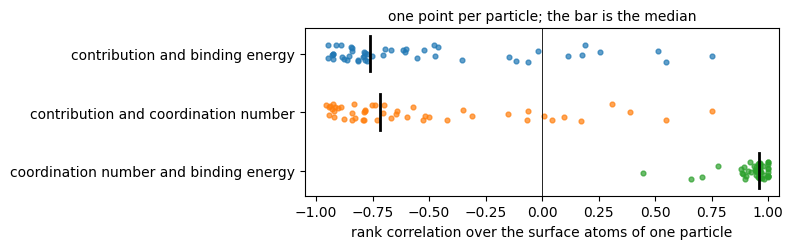

In [11]:
rows = X["rows"]
fig, ax = plt.subplots(figsize=(8, 2.6))
series = [("contribution and binding energy", "spearman"),
          ("contribution and coordination number", "spearman_coordination"),
          ("coordination number and binding energy", "spearman_coordination_binding")]
rng = np.random.default_rng(0)
for i, (label, key) in enumerate(series):
    v = np.array([r[key] for r in rows if r[key] is not None])
    ax.scatter(v, i + rng.uniform(-0.15, 0.15, len(v)), s=12, alpha=0.7)
    ax.plot([np.median(v)] * 2, [i - 0.3, i + 0.3], color="black", lw=2)
ax.axvline(0, color="black", lw=0.6)
ax.set_yticks(range(len(series)))
ax.set_yticklabels([s[0] for s in series])
ax.invert_yaxis()
ax.set_xlim(-1.05, 1.05)
ax.set_xlabel("rank correlation over the surface atoms of one particle")
ax.set_title("one point per particle; the bar is the median", fontsize=10)
plt.tight_layout()
plt.show()

## What to take from this notebook

- When the question is which atom of a particle binds, make the site the sample. A model of the
  whole particle predicts the mean but its split over the atoms follows the coordination number,
  not the binding.
- The binding of OH follows the generalized coordination number (correlation 0.914 on gold and
  0.835 on platinum), but a line in it is the weakest model here.
- The site profile with the core fields is the best model: q² 0.929 with particles held out and
  0.920 with shapes held out. Most of its lead over neighbour counts is one number, the exposure
  of the site. A Gaussian kernel on the counts, the two coordination numbers and the exposure
  comes within 0.004 and 0.016, and with the core values of each shell it is level on new
  particles. Only on a new shape does the profile keep a lead of about 0.02.
- A better model of the energies does not find the strongest site more often: every model finds
  it in 31 to 39 of 48 particles.

The reference of this notebook is a stage of the benchmark of plan item NT7; this command
measures it again and writes it to `benchmarks/results/particle_sites/table.md` (about 70
minutes):

```
python benchmarks/run_particle_sites.py --stage references
```

From the command line, a site model is fitted with `cmf build-crystals particles.extxyz
--site-file sites.csv --fields steric,prop:coordination,prop:generalized_coordination,prop:exposure`
and applied to every site of a new particle with `cmf sites`. The Gaussian kernel on the numbers
of the site is `gaussian_per_metal` in `benchmarks/run_particle_sites.py`.

Where to read further in the manual: *Crystals and other periodic structures* has the site model of
particles, its data and this benchmark; *A site of the cell as the sample: the split of the
autocorrelation* explains the site profile and the split of a whole-structure model.